In [26]:
import re

def compute_costs(log_file_path):
    costs = []
    cost = 0
    generations = -1
    with open(log_file_path, 'r') as log_file:
        for line in log_file:
            if "generations" in line:
                generations += 1
                costs.append(cost)
            if "$" in line:
                # Extract the number after $
                match = re.search(r'\$([0-9.]+)', line)
                if match:
                    cost += float(match.group(1))
    return costs

approach_one = compute_costs("results_scheduling/evolution_run.log")
approach_two = compute_costs("results_scheduling_2/evolution_run.log")
approach_one, approach_two

([0,
  0,
  0.09949999999999999,
  0.2196,
  0.35000000000000003,
  0.4861,
  0.6494,
  0.8112999999999999,
  1.0779999999999996,
  1.5113999999999999,
  2.0859,
  2.3465,
  2.4768999999999997,
  2.6201999999999996,
  3.2833999999999985,
  3.624699999999998,
  3.8443999999999976,
  4.004199999999998,
  4.270099999999998,
  4.562599999999997,
  5.343599999999997,
  5.419199999999997,
  5.541599999999998,
  5.7685999999999975,
  6.001799999999998,
  6.186999999999998,
  6.260399999999998,
  6.369899999999998,
  6.561899999999998,
  6.676399999999998,
  7.112499999999997,
  7.1896999999999975,
  7.2784999999999975,
  7.395499999999998,
  7.615399999999999,
  7.8378999999999985,
  8.2626,
  8.6026,
  8.795800000000002,
  9.1381,
  9.4775,
  9.560099999999998,
  9.903899999999997,
  10.230999999999993,
  10.272099999999991,
  10.464399999999992,
  10.629099999999992,
  10.957499999999992,
  11.108499999999992,
  11.247899999999992,
  11.807199999999993,
  11.961999999999993,
  12.1605999999

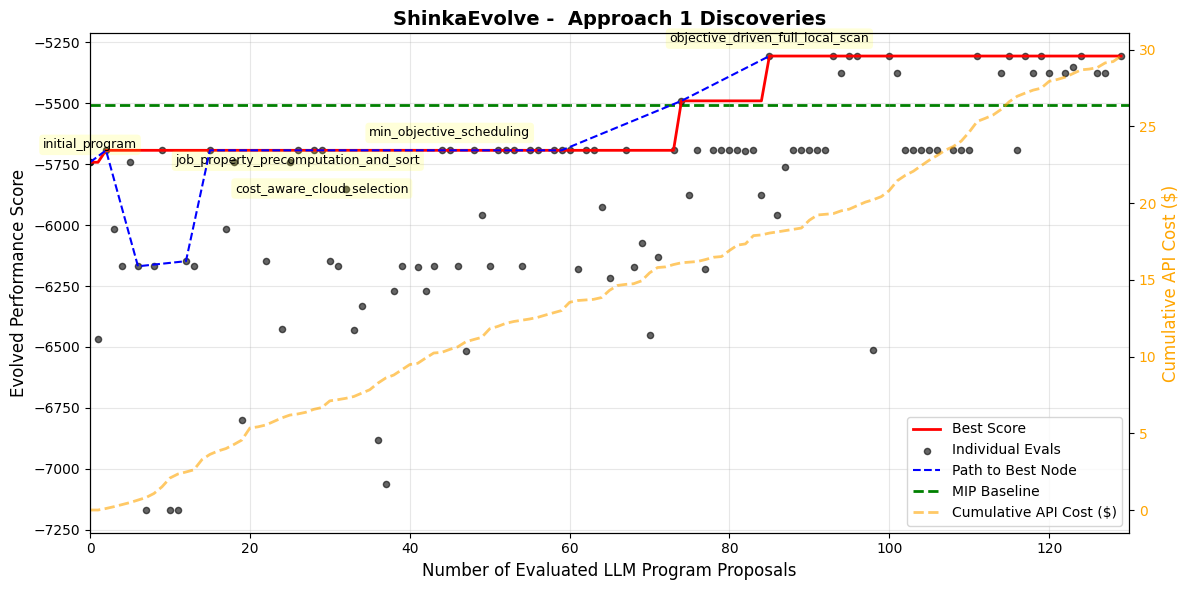

In [ ]:
import sqlite3
import matplotlib.pyplot as plt
from pathlib import Path
import json

results_dir = "results_scheduling"
results_path = Path(results_dir)

# Load data from database
conn = sqlite3.connect(results_path / "evolution_db.sqlite")
cursor = conn.cursor()
cursor.execute("SELECT generation, combined_score, id, parent_id FROM programs WHERE combined_score != 0 ORDER BY generation")
programs = cursor.fetchall()

# Organize by generation
gen_scores = {}
for gen, score, prog_id, parent_id in programs:
    if gen not in gen_scores:
        gen_scores[gen] = []
    gen_scores[gen].append(score)

# Get best scores per generation (cumulative max)
generations = sorted(gen_scores.keys())
best_scores = []
current_best = float('-inf')
for g in generations:
    gen_best = max(gen_scores[g])
    current_best = max(current_best, gen_best)
    best_scores.append(current_best)

# Get all individual scores
all_gens = [p[0] for p in programs]
all_scores = [p[1] for p in programs]

# Trace lineage to best
program_dict = {p[2]: p for p in programs}
best_prog = max(programs, key=lambda x: x[1])
lineage = []
current_id = best_prog[2]
while current_id in program_dict:
    lineage.append(program_dict[current_id])
    parent_id = program_dict[current_id][3]
    if not parent_id or parent_id not in program_dict:
        break
    current_id = parent_id
lineage.reverse()
lineage_gens = [p[0] for p in lineage]
lineage_scores = [p[1] for p in lineage]
lineage_ids = [p[2] for p in lineage]

# Get algorithm names from metadata
cursor.execute(f"SELECT id, metadata FROM programs WHERE id IN ({','.join(['?']*len(lineage_ids))})", lineage_ids)
lineage_metadata = {row[0]: row[1] for row in cursor.fetchall()}
conn.close()

# Extract and format patch names
lineage_names = []
for i, prog_id in enumerate(lineage_ids):
    if prog_id in lineage_metadata:
        try:
            metadata = json.loads(lineage_metadata[prog_id])
            patch_name = metadata.get('patch_name', 'none')
            if patch_name == 'none' or not patch_name:
                patch_name = f"gen_{lineage_gens[i]}"
            else:
                # Format: lowercase with underscores, truncate if too long
                patch_name = patch_name.lower().replace(' ', '_').replace('-', '_')
                # if len(patch_name) > 20:
                    # patch_name = patch_name[:17] + "..."
            lineage_names.append(patch_name)
        except:
            lineage_names.append(f"gen_{lineage_gens[i]}")
    else:
        lineage_names.append(f"gen_{lineage_gens[i]}")

# Create plot
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot data
ax1.plot(generations, best_scores, 'r-', linewidth=2, label='Best Score', zorder=3)
ax1.scatter(all_gens, all_scores, c='black', s=20, alpha=0.6, label='Individual Evals', zorder=2)
ax1.plot(lineage_gens, lineage_scores, 'b--', linewidth=1.5, label='Path to Best Node', zorder=4)
ax1.axhline(y=-5508, color='green', linestyle='--', linewidth=2, label='MIP Baseline', zorder=1)

# Annotate lineage with algorithm names (all points with names)
annotations_to_show = [(gen, score, name) for gen, score, name in zip(lineage_gens, lineage_scores, lineage_names) 
                       if not name.startswith('gen_')]

# Offset annotations that are close to each other
offset_counter = 0
for i, (gen, score, name) in enumerate(annotations_to_show):
    # Check if next annotation is close (within 10 units on x-axis)
    if i < len(annotations_to_show) - 1:
        next_gen = annotations_to_show[i + 1][0]
        if abs(next_gen - gen) < 20:
            y_offset = -(10 + (offset_counter % 3) * 20)
            offset_counter += 1
        else:
            y_offset = 10
            offset_counter = 0
    else:
        y_offset = 10
    
    ax1.annotate(name, (gen, score), textcoords="offset points", xytext=(0, y_offset), 
                ha='center', fontsize=9, rotation=0,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.15, edgecolor='none'))

ax1.set_xlabel('Number of Evaluated LLM Program Proposals', fontsize=12)
ax1.set_ylabel('Evolved Performance Score', fontsize=12)
ax1.set_xlim(0, 150)
ax1.grid(True, alpha=0.3)

# Add secondary y-axis for cumulative cost
ax2 = ax1.twinx()
cost_gens = list(range(len(approach_one)))
ax2.plot(cost_gens, approach_one, 'orange', linestyle='--', linewidth=2, 
         alpha=0.6, label='Cumulative API Cost ($)', zorder=1)
ax2.set_ylabel('Cumulative API Cost ($)', fontsize=12, color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', fontsize=10)

plt.title('ShinkaEvolve -  Approach 1 Discoveries', fontsize=14, fontweight='bold')
plt.tight_layout()
# plt.savefig(results_path / 'evolution_progress.png', dpi=300, bbox_inches='tight')
plt.show()

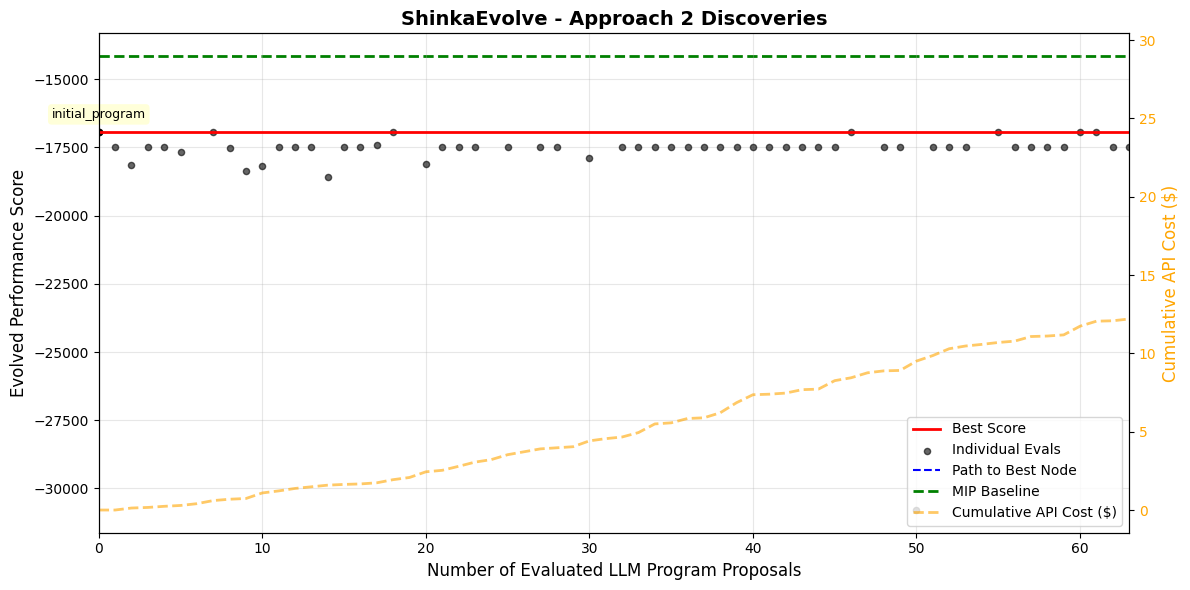

In [ ]:
import sqlite3
import matplotlib.pyplot as plt
from pathlib import Path
import json

results_dir = "results_scheduling_2"
results_path = Path(results_dir)

# Load data from database
conn = sqlite3.connect(results_path / "evolution_db.sqlite")
cursor = conn.cursor()
cursor.execute("SELECT generation, combined_score, id, parent_id FROM programs WHERE combined_score != 0 ORDER BY generation")
programs = cursor.fetchall()

# Organize by generation
gen_scores = {}
for gen, score, prog_id, parent_id in programs:
    if gen not in gen_scores:
        gen_scores[gen] = []
    gen_scores[gen].append(score)

# Get best scores per generation (cumulative max)
generations = sorted(gen_scores.keys())
best_scores = []
current_best = float('-inf')
for g in generations:
    gen_best = max(gen_scores[g])
    current_best = max(current_best, gen_best)
    best_scores.append(current_best)

# Get all individual scores
all_gens = [p[0] for p in programs]
all_scores = [p[1] for p in programs]

# Trace lineage to best
program_dict = {p[2]: p for p in programs}
best_prog = max(programs, key=lambda x: x[1])
lineage = []
current_id = best_prog[2]
while current_id in program_dict:
    lineage.append(program_dict[current_id])
    parent_id = program_dict[current_id][3]
    if not parent_id or parent_id not in program_dict:
        break
    current_id = parent_id
lineage.reverse()
lineage_gens = [p[0] for p in lineage]
lineage_scores = [p[1] for p in lineage]
lineage_ids = [p[2] for p in lineage]

# Get algorithm names from metadata - get all programs
cursor.execute("SELECT id, metadata FROM programs")
all_metadata = {row[0]: row[1] for row in cursor.fetchall()}
conn.close()

# Extract and format patch names for lineage
lineage_names = []
for i, prog_id in enumerate(lineage_ids):
    if prog_id in all_metadata:
        try:
            metadata = json.loads(all_metadata[prog_id])
            patch_name = metadata.get('patch_name', 'none')
            if patch_name == 'none' or not patch_name:
                patch_name = f"gen_{lineage_gens[i]}"
            else:
                patch_name = patch_name.lower().replace(' ', '_').replace('-', '_')
            lineage_names.append(patch_name)
        except:
            lineage_names.append(f"gen_{lineage_gens[i]}")
    else:
        lineage_names.append(f"gen_{lineage_gens[i]}")

# Create plot
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot data
ax1.plot(generations, best_scores, 'r-', linewidth=2, label='Best Score', zorder=3)
ax1.scatter(all_gens, all_scores, c='black', s=20, alpha=0.6, label='Individual Evals', zorder=2)
ax1.plot(lineage_gens, lineage_scores, 'b--', linewidth=1.5, label='Path to Best Node', zorder=4)
ax1.axhline(y=-14154, color='green', linestyle='--', linewidth=2, label='MIP Baseline', zorder=1)

# Annotate lineage with algorithm names (all points with names)
annotations_to_show = [(gen, score, name) for gen, score, name in zip(lineage_gens, lineage_scores, lineage_names) 
                       if not name.startswith('gen_')]

# Offset annotations that are close to each other
offset_counter = 0
for i, (gen, score, name) in enumerate(annotations_to_show):
    if i < len(annotations_to_show) - 1:
        next_gen = annotations_to_show[i + 1][0]
        if abs(next_gen - gen) < 20:
            y_offset = -(10 + (offset_counter % 3) * 20)
            offset_counter += 1
        else:
            y_offset = 10
            offset_counter = 0
    else:
        y_offset = 10
    
    ax1.annotate(name, (gen, score), textcoords="offset points", xytext=(0, y_offset), 
                ha='center', fontsize=9, rotation=0,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.15, edgecolor='none'))

# Annotate programs that match the best score at each generation
for gen, score, prog_id, parent_id in programs:
    if gen in gen_scores:
        gen_best = max(gen_scores[gen])
        if score == gen_best and prog_id not in lineage_ids:
            if prog_id in all_metadata:
                try:
                    metadata = json.loads(all_metadata[prog_id])
                    patch_name = metadata.get('patch_name', 'none')
                    if patch_name != 'none' and patch_name:
                        patch_name = patch_name.lower().replace(' ', '_').replace('-', '_')
                        ax1.annotate(patch_name, (gen, score), textcoords="offset points", xytext=(5, 5), 
                                    ha='left', fontsize=8, rotation=0,
                                    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgreen', alpha=0.15, edgecolor='none'))
                except:
                    pass

ax1.set_xlabel('Number of Evaluated LLM Program Proposals', fontsize=12)
ax1.set_ylabel('Evolved Performance Score', fontsize=12)
ax1.set_xlim(0, 63)
ax1.grid(True, alpha=0.3)

# Add secondary y-axis for cumulative cost
ax2 = ax1.twinx()
cost_gens = list(range(len(approach_two)))
ax2.plot(cost_gens, approach_two, 'orange', linestyle='--', linewidth=2, 
         alpha=0.6, label='Cumulative API Cost ($)', zorder=1)
ax2.set_ylabel('Cumulative API Cost ($)', fontsize=12, color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', fontsize=10)

plt.title('ShinkaEvolve - Approach 2 Discoveries', fontsize=14, fontweight='bold')
plt.tight_layout()
# plt.savefig(results_path / 'evolution_progress.png', dpi=300, bbox_inches='tight')
plt.show()